In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
def calculate_accuracy(classifier, X_train, X_test, y_train, y_test):
    classifier.fit(X_train, y_train)
    y_pred_train = classifier.predict(X_train)
    y_pred_test = classifier.predict(X_test)
    accuracy_train = metrics.accuracy_score(y_train, y_pred_train)
    accuracy_test = metrics.accuracy_score(y_test, y_pred_test)
    print('Train accuracy:', '{:.3f}'.format(accuracy_train), 'Test accuracy:', '{:.3f}'.format(accuracy_test))
    return accuracy_train, accuracy_test, classifier

In [ ]:
random_state = 42
data = pd.read_csv('/content/drive/MyDrive/ai4omics-DataFiles/data/colon_cancer.csv', sep=';', index_col='id_sample')
print('data', data.shape)
y = data['tissue_status']
print('y', y.shape)

In [ ]:
x = data.select_dtypes('number')
print(x)

                    ADH1C    DHRS11      UGP2    SLC7A5      CTSS       DAO  \
id_sample                                                                     
EPSM-COLON-0001  9.199944  6.090054  7.062512  3.864253  7.869368  8.465133   
EPSM-COLON-0002  7.767618  6.027985  6.318818  3.069581  6.410334  8.159814   
EPSM-COLON-0003  7.918904  5.885948  6.917742  3.188257  7.915549  8.004194   
EPSM-COLON-0004  9.053553  6.027985  7.081085  2.357523  5.657726  8.004194   
EPSM-COLON-0005  6.027822  5.791257  5.937685  4.137667  5.818999  8.056067   
...                   ...       ...       ...       ...       ...       ...   
EPSM-COLON-0800  6.019963  3.089364  4.393486  5.947781  7.124598  6.476207   
EPSM-COLON-0801  3.691606  2.118164  4.794787  4.746829  5.493405  5.127365   
EPSM-COLON-0802  3.035242  2.495383  4.438451  5.916828  7.155135  5.556266   
EPSM-COLON-0803  3.021057  3.581192  4.822947  5.694947  6.789079  6.570513   
EPSM-COLON-0804  0.957801  1.800005  4.985909  3.844

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=1/4, random_state=random_state, stratify=y)

In [ ]:
print('train:', x_train.shape, 'test:', x_test.shape)

train: (603, 60) test: (201, 60)


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(x_train)


StandardScaler()

In [ ]:
print ('Mean mu', scaler.mean_)

Mean mu [5.56250784 4.37031229 5.5576452  4.5032885  6.70477296 7.20224541
 2.73722189 2.83883913 3.09567408 3.62783178 4.9956429  8.00645284
 2.13428824 3.25051517 5.72798593 2.602014   5.09621073 4.95027125
 5.12856168 2.60945896 4.57087133 2.61901627 4.00316847 2.83774532
 5.05378073 4.70302486 4.48579809 5.2552879  5.10330709 3.87416991
 4.42493323 3.41604512 2.99677417 3.12825274 3.21237453 2.94096313
 4.059025   2.56226458 4.03283796 2.46987601 3.61611895 3.06480367
 4.18373897 3.33961906 4.60751801 3.22049712 4.79100352 3.19601853
 2.16639761 5.46168857 3.59541576 4.6518569  4.25604076 4.60405964
 4.10572903 1.79212905 2.84821267 6.10344378 2.81507307 2.61131882]


In [ ]:
print('Std sigma', scaler.scale_)

Std sigma [2.87450773 1.41750502 1.16900926 1.62727559 1.08192036 1.39528512
 1.4405307  1.25002277 1.20996386 1.2651503  0.7258847  3.02651441
 0.6970907  0.8496204  1.10564825 1.29408208 1.25535892 2.70235274
 0.83604128 1.45557859 1.36504482 0.89653108 0.89616633 0.74177497
 0.76354578 1.08303667 0.89196864 1.07683176 1.1278559  0.959783
 0.94799683 0.95342434 0.95399801 1.05874883 0.91663639 0.79398048
 0.86882235 0.95497763 0.74386269 0.79827373 0.58288541 1.14404363
 0.75023715 0.78168341 1.51741848 0.91180632 1.10693458 1.12902104
 0.83743434 1.17059202 1.06519408 0.93742726 1.65998753 0.86348611
 1.26049718 0.70875365 1.33154111 0.84309529 1.02498105 0.99669006]


In [ ]:
x_train_scaled = scaler.transform(x_train)  # numpy object_below code to convert it to pandas dataframe
x_train_scaled=pd.DataFrame(x_train_scaled, index=x_train.index, columns=x_train.columns)

In [ ]:
x_test_scaled = scaler.transform(x_test) # this code is to convert numpy object it to pandas dataframe
x_test_scaled = pd.DataFrame(x_test_scaled, index=x_test.index, columns=x_test.columns)

In [ ]:
x_train_scaled.mean().head()

,0
ADH1C,7.070077e-17
DHRS11,-1.414015e-16
UGP2,-6.598739e-16
SLC7A5,-1.178346e-16
CTSS,1.089970e-16


In [ ]:
x_train_scaled.std().head(100)

,0
ADH1C,1.00083
DHRS11,1.00083
UGP2,1.00083
SLC7A5,1.00083
CTSS,1.00083
DAO,1.00083
NIBAN1,1.00083
PRUNE2,1.00083
FOXF2,1.00083
TENT5C,1.00083


In [ ]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state=random_state, penalty='l2')
print(classifier)

LogisticRegression(random_state=42)


In [ ]:
accuracy_train, accuracy_test, trained_classifier = calculate_accuracy(classifier, x_train_scaled, x_test_scaled, y_train, y_test)

Train accuracy: 1.000 Test accuracy: 1.000


In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

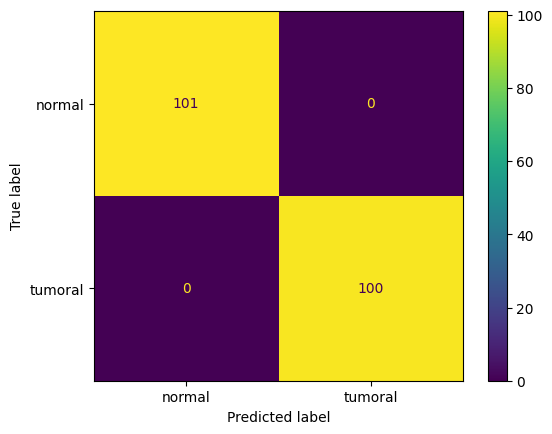

In [19]:
ConfusionMatrixDisplay.from_estimator(trained_classifier, x_test_scaled, y_test)

In [20]:
coefficients = pd.DataFrame(trained_classifier.coef_[0], index=x_train_scaled.columns, columns=['beta'])
coefficients.head(10)

,beta
ADH1C,-0.458303
DHRS11,-0.408084
UGP2,-0.707553
SLC7A5,0.880985
CTSS,-0.116125
DAO,-0.705497
NIBAN1,-0.451329
PRUNE2,0.010307
FOXF2,-0.459195
TENT5C,-0.366729


<Axes: >

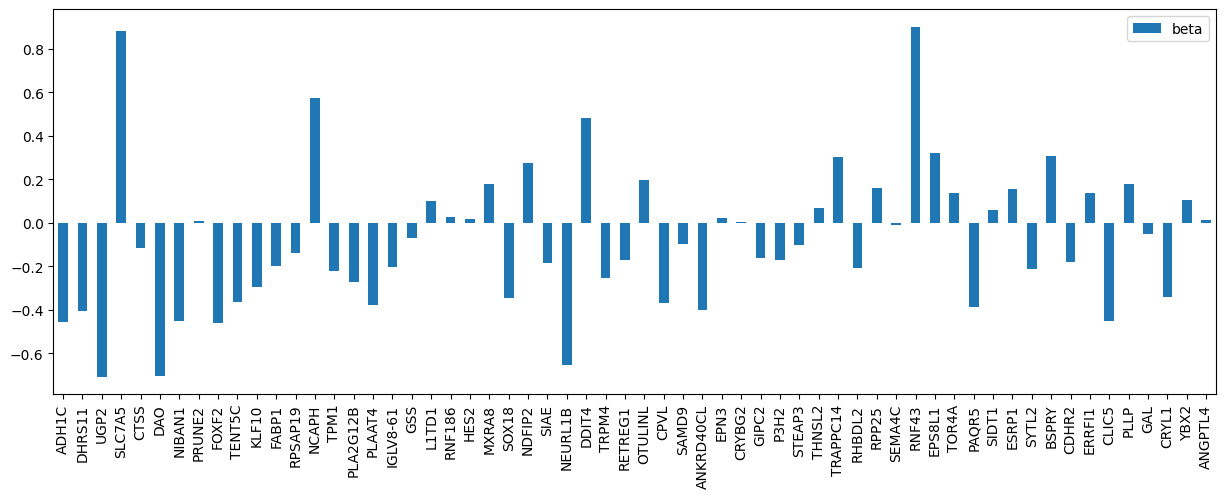

In [21]:
Coefficients = coefficients.sort_values(by='beta')
coefficients.plot.bar(figsize=(15, 5))

In [22]:
n_features = 3
coefficients['abs_beta'] = coefficients['beta'].abs()
coefficients = coefficients.sort_values(by='abs_beta', ascending=False) # sort by absolute values
top_features = list(coefficients.head(n_features).index)
print('Top features of LR:', top_features)

Top features of LR: ['RNF43', 'SLC7A5', 'UGP2']


In [23]:
for i in range(len(top_features)):
    selected_features = top_features[0:i+1]
    print(selected_features)
    accuracy_train, accuracy_test, trained_classifier = calculate_accuracy(classifier, x_train_scaled[selected_features], x_test_scaled[selected_features], y_train, y_test)

['RNF43']
Train accuracy: 0.924 Test accuracy: 0.841
['RNF43', 'SLC7A5']
Train accuracy: 0.960 Test accuracy: 0.935
['RNF43', 'SLC7A5', 'UGP2']
Train accuracy: 0.990 Test accuracy: 0.990


Case study

In [24]:
panelof3 = ['RNF43', 'SLC7A5', 'DAO']

In [25]:
new_patient = {'RNF43': 4.68, 'SLC7A5': 4.10, 'DAO': 7.59}

In [26]:
xx_train = data[panelof3]
yy_train = y
xx_train.head()

,RNF43,SLC7A5,DAO
id_sample,,,
EPSM-COLON-0001,4.241267,3.864253,8.465133
EPSM-COLON-0002,4.002000,3.069581,8.159814
EPSM-COLON-0003,3.447174,3.188257,8.004194
EPSM-COLON-0004,3.655234,2.357523,8.004194
EPSM-COLON-0005,3.863294,4.137667,8.056067


In [27]:
xx_test = pd.DataFrame([new_patient], index=['new_patient'])
xx_test

,RNF43,SLC7A5,DAO
new_patient,4.68,4.1,7.59


In [28]:
scaler = StandardScaler()
scaler.fit(xx_train)
xx_train_scaled = scaler.transform(xx_train)
xx_test_scaled = scaler.transform(xx_test)

classifier = LogisticRegression(random_state=random_state, penalty='l2')
classifier.fit(xx_train_scaled,yy_train)
yy_new_patient = classifier.predict(xx_test_scaled)
print(classifier,yy_new_patient)


LogisticRegression(random_state=42) ['normal']
